# 2 · Models, objectives and FedAvg

**Question:** What do the models compute, and what does the server average?

For readers comfortable with inputs, hidden layers and class scores. We use the
**actual model constructors**, inspect tensor shapes and parameter counts, then
work through a tiny arithmetic example of FedAvg. The arithmetic example and
zero-input forward pass are teaching demonstrations, not fitted ECG results.

**Route:** architectures → two input branches → weighted aggregation → objectives.

[Notebook guide](README.md) · [Full model definitions](../fedecg/models.py)

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'fedecg/models.py').is_file())
sys.path.insert(0, str(ROOT))
from notebooks._support import CLASSES, COLORS, NAMES, read_table, read_json, setup, finish
setup()
%matplotlib inline

In [2]:
import torch
from fedecg.models import make_model, class_weights

torch.manual_seed(7)
torch.set_num_threads(1)
architectures = ['mlp', 'mlp_rr', 'cnn', 'cnn_rr', 'cnn_spatial_rr']
waveform, rr = torch.zeros(2, 1, 252), torch.zeros(2, 4)
rows = []
for name in architectures:
    model = make_model(name).eval()
    with torch.no_grad():
        scores = model(waveform, rr)
    count = sum(p.numel() for p in model.parameters())
    rows.append({'Model': NAMES[name], 'Parameters': count,
                 'FP32 parameter bytes': 4 * count, 'Output shape': str(tuple(scores.shape))})
    assert scores.shape == (2, 5)
table = pd.DataFrame(rows).set_index('Model')
assert table.Parameters.tolist() == [40965, 46837, 17733, 17989, 75125]
display(table)

,Parameters,FP32 parameter bytes,Output shape
Model,,,
MLP,40965,163860,"(2, 5)"
MLP + RR,46837,187348,"(2, 5)"
Compact CNN,17733,70932,"(2, 5)"
Compact CNN + RR,17989,71956,"(2, 5)"
Spatial CNN + RR,75125,300500,"(2, 5)"


## Where does each model spend its parameters?

The MLP reads the 252 samples as one vector. Compact CNNs learn local temporal
filters and average the final feature map over time. The spatial CNN retains
31 aligned positions before its dense layer, so it has more parameters despite
fewer final channels. Each model returns five logits; softmax converts those
scores to probabilities for inference.

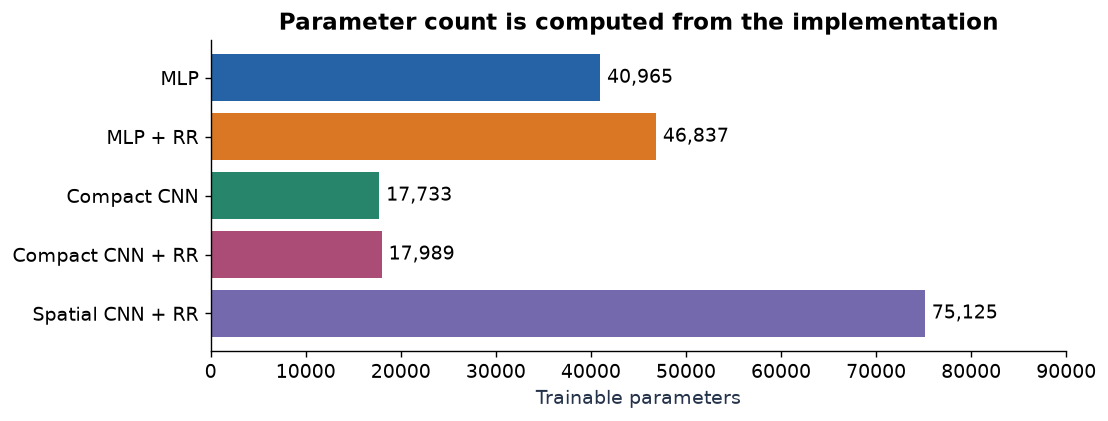

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.barh(table.index, table.Parameters, color=COLORS)
ax.bar_label(bars, labels=[f'{n:,}' for n in table.Parameters], padding=4)
ax.set(xlim=(0, 90000), xlabel='Trainable parameters', title='Parameter count is computed from the implementation')
ax.invert_yaxis()
finish(fig)

## The MLP + RR model combines shape and timing

One branch embeds waveform morphology; another embeds four past-RR features.
The two embeddings have 64 and 16 values. Concatenating them gives 80 values,
followed by a 64-unit layer and five output logits. Timing features add context;
whether that context improves generalization is an empirical question.

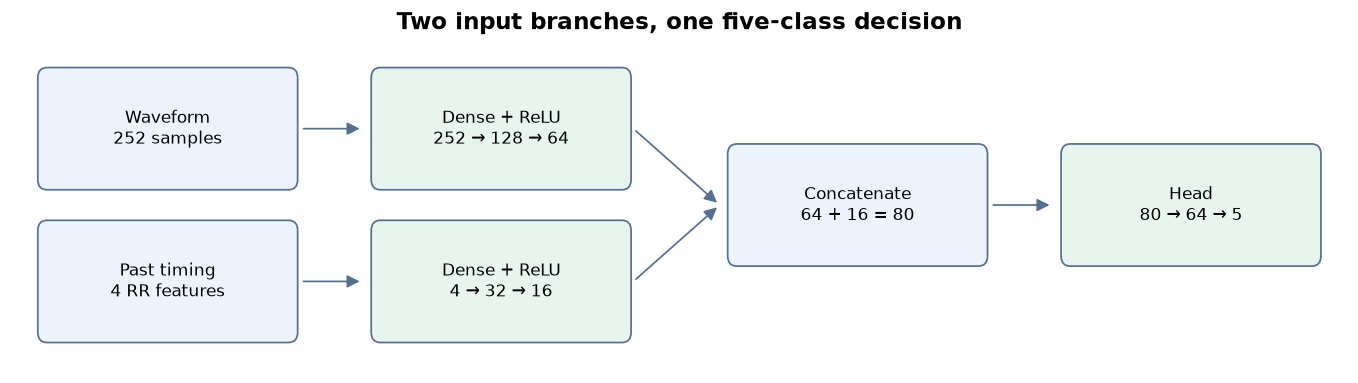

In [4]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 3.2))
boxes = [(0, 1.2, 'Waveform\n252 samples'), (2.9, 1.2, 'Dense + ReLU\n252 → 128 → 64'),
         (0, 0, 'Past timing\n4 RR features'), (2.9, 0, 'Dense + ReLU\n4 → 32 → 16'),
         (6, .6, 'Concatenate\n64 + 16 = 80'), (8.9, .6, 'Head\n80 → 64 → 5')]
for i, (x, y, label) in enumerate(boxes):
    ax.add_patch(FancyBboxPatch((x, y), 2.1, .8, boxstyle='round,pad=.08',
                               facecolor='#edf3fa' if i % 2 == 0 else '#e8f4ee', edgecolor='#54708e'))
    ax.text(x + 1.05, y + .4, label, ha='center', va='center', fontsize=10)
for a, b in [(0, 1), (2, 3), (1, 4), (3, 4), (4, 5)]:
    x, y, _ = boxes[a]; u, v, _ = boxes[b]
    ax.add_patch(FancyArrowPatch((x + 2.2, y + .4), (u - .15, v + .4),
                                arrowstyle='-|>', mutation_scale=15, color='#54708e'))
ax.set(xlim=(-.3, 11.3), ylim=(-.3, 2.3), title='Two input branches, one five-class decision')
ax.axis('off')
finish(fig)

## FedAvg averages parameters in proportion to training counts

In the primary runs each client starts a round from the same global state,
uses one local epoch of AdamW, and returns its local state. The optimizer is
reset per client and round. The server computes

$$w_{t+1}=\sum_{k\in\mathcal{K}_t}\frac{n_k}{\sum_j n_j}w_{t+1}^{(k)}.$$

Here is a **two-client, two-parameter toy example**. Client A has three
examples and client B has one; their aggregation weights are 0.75 and 0.25.
These made-up vectors explain the averaging rule only.

,Client,Examples,Weight,Parameter 1,Parameter 2
0,A,3,0.75,1.0,-1.0
1,B,1,0.25,3.0,1.0


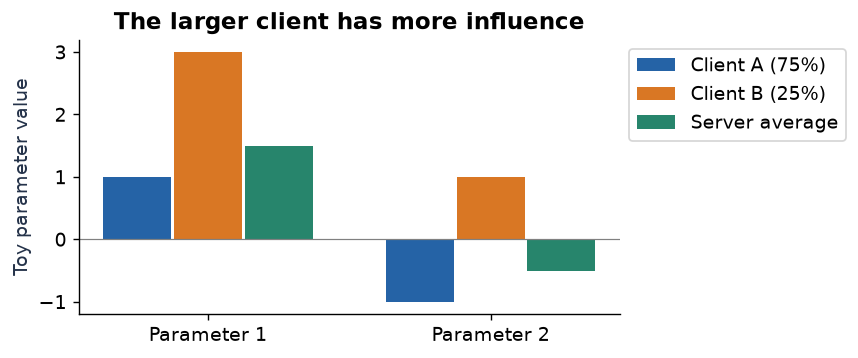

In [5]:
local_states = np.array([[1., -1.], [3., 1.]])
counts = np.array([3, 1])
weights = counts / counts.sum()
server_state = np.sum(weights[:, None] * local_states, axis=0)
assert np.allclose(server_state, [1.5, -.5])
display(pd.DataFrame({'Client': ['A', 'B'], 'Examples': counts, 'Weight': weights,
                      'Parameter 1': local_states[:, 0], 'Parameter 2': local_states[:, 1]}))
fig, ax = plt.subplots(figsize=(7, 3))
positions = np.arange(2)
for offset, values, label, color in [(-.25, local_states[0], 'Client A (75%)', COLORS[0]),
                                    (0, local_states[1], 'Client B (25%)', COLORS[1]),
                                    (.25, server_state, 'Server average', COLORS[2])]:
    ax.bar(positions + offset, values, width=.24, label=label, color=color)
ax.axhline(0, color='gray', lw=.7)
ax.set(xticks=positions, xticklabels=['Parameter 1', 'Parameter 2'], ylabel='Toy parameter value', title='The larger client has more influence')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
finish(fig)

## Class weighting changes the local objective

Ordinary cross-entropy gives each example equal weight. The weighted and
balanced variants use capped square-root inverse frequency and capped inverse
frequency respectively, based on **pooled training-only counts**. Present-class
weights are normalized to mean one. Focal loss also downweights easy examples.
The aggregation rule remains sample-count FedAvg.

In [6]:
support = read_table('main_patient_class_support.csv')
counts = support.query("split == 'training'").groupby('class').beats.sum().reindex(CLASSES)
y = torch.repeat_interleave(torch.arange(5), torch.tensor(counts.to_numpy()))
objectives = pd.DataFrame({'Training support': counts.to_numpy(), 'CE': np.ones(5),
                          'Weighted CE': class_weights(y, 'weighted').numpy(),
                          'Balanced CE': class_weights(y, 'balanced').numpy()}, index=CLASSES)
display(objectives.round(4))

,Training support,CE,Weighted CE,Balanced CE
N,36723,1.0,0.1508,0.0176
S,421,1.0,1.4081,1.5360
V,2582,1.0,0.5686,0.2505
F,408,1.0,1.4304,1.5850
Q,8,1.0,1.4421,1.6109


### Try it: do the two-client average with equal weights

Predict which of the two parameter values moves most. Then run the next cell
to check your answer, or change `equal_weights` to try another allocation.

In [7]:
equal_weights = np.array([.5, .5])
equal_state = equal_weights @ local_states
display(pd.DataFrame({'Sample-weighted': server_state, 'Equal-weighted': equal_state},
                     index=['Parameter 1', 'Parameter 2']))
# Both move by +0.5. Equal client weighting defines a different aggregation rule.

,Sample-weighted,Equal-weighted
Parameter 1,1.5,2.0
Parameter 2,-0.5,0.0


**Pitfall:** the zero-input forward pass verifies dimensions, not model quality.
Likewise, a bigger class weight does not establish better rare-class recall.
The next notebook examines the saved predictive results.

**Optional extension:** print `make_model('cnn_spatial_rr')` and follow the
pooled lengths 252 → 126 → 63 → 31 through the encoder.

**Next:** [3 · Results and uncertainty](03_results_and_uncertainty.ipynb)